# 03 · Más allá de los mínimos

Experimentos ejecutados cambiando **un solo factor** frente a DQN (01) o A3C (02).
Se cubren todas las ideas de partida: Double DQN, duelo, red objetivo, clipping,
A2C, historia de retornos, MA30 y volatilidad, otros mercados, S&P 500, comisiones,
recompensa logarítmica, placebo y mezcla de generadores.

**Este análisis es posterior al test oficial.** Las cifras de 01 y 02 se conservan.
El plan se fija antes del nuevo barrido y no se eligen variantes con sus resultados.
Diseño completo: [03_METODOLOGIA.md](../results/03_METODOLOGIA.md), decisión D-3.1.

In [1]:
import ast
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd() if Path.cwd().name == "notebooks" else Path.cwd() / "notebooks"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from common.extras import CORE_MARKETS, ExtraConfig, make_plan, run_suite
from common.extras_report import (commission_figure, effect_figure, export_series, load_grid,
                                  performance_table, real_figure, seed_ranges)
from common.protocol import RESULTS_DIR, convergence_status
from common.style import MARKET_LABELS, formato, setup

torch.set_num_threads(1)
setup()
N_JOBS = 6  # ajustar según memoria y núcleos; los resultados completados se leen de caché

## 1. Protocolo y plan previo

- **5 semillas, 500 episodios, 494 decisiones por episodio**; misma DQN y parámetros que 01.
- Una serie nueva por episodio. Se reentrena también la referencia con el mismo software.
- Normalización solo de train; validación fija de 20 series cada 25 episodios.
- **400 series sintéticas nuevas por mercado desde 600.000**. Ni el test oficial (100.000)
  ni las series de mejoras anteriores (400.000) se usan aquí.
- Parejas con las mismas series y semillas. La ventaja es la mediana entre semillas de la
  mediana por serie de `log(capital_variante / capital_referencia)`.
- Se conserva el margen de ruido de 01–02: log(1,25), 0,10, 0,02 y 0,10 según mercado.
  Es un criterio descriptivo, **no un contraste de significación**. Se muestran también
  rango y número de semillas que mejoran.
- No se combinan mejoras ni se retocan hiperparámetros después de observar estas series.

Al ampliar el estado aumenta también el tamaño de la capa de entrada: es parte del factor
«representación». Los indicadores usan únicamente historia disponible y el inicio del
episodio no cambia. No se modifica `SimpleTradingEnv` ni los cuatro generadores originales.

In [2]:
plan = make_plan()
plan_table = pd.DataFrame([{k: job[k] for k in ("variante", "mercado", "seed", "factor")} for job in plan])
display(plan_table.groupby(["variante", "factor"], sort=False).agg(
    entrenamientos=("seed", "size"), mercados=("mercado", lambda x: ", ".join(dict.fromkeys(x)))) )
print(f"Plan: {len(plan)} entrenamientos DQN y 40 de A2C/A3C. Cada DQN difiere como máximo en una clave de su base.")

,,entrenamientos,mercados
variante,factor,,
base,ninguno,20,"tendencia_ciclo, browniano, reversion_media, r..."
doble,double,20,"tendencia_ciclo, browniano, reversion_media, r..."
duelo,dueling,20,"tendencia_ciclo, browniano, reversion_media, r..."
sin_objetivo,use_target,20,"tendencia_ciclo, browniano, reversion_media, r..."
clip,reward_clip,20,"tendencia_ciclo, browniano, reversion_media, r..."
ventana,features,20,"tendencia_ciclo, browniano, reversion_media, r..."
ma30_vol,features,20,"tendencia_ciclo, browniano, reversion_media, r..."
log,log_reward,20,"tendencia_ciclo, browniano, reversion_media, r..."
ciego,features,20,"tendencia_ciclo, browniano, reversion_media, r..."


Plan: 260 entrenamientos DQN y 40 de A2C/A3C. Cada DQN difiere como máximo en una clave de su base.


## 2. Variantes de DQN

Se prueba cada cambio de forma independiente en los cuatro mercados:

| Variante | Cambio | Hipótesis previa |
|---|---|---|
| Double DQN | Online selecciona; target valora | Reducir sobreestimación puede estabilizar Q |
| Duelo | Q=V+A−media(A) | Separar valor del estado y acción puede ayudar con acciones de valor similar |
| Sin red objetivo | Se usa online para calcular el objetivo | Medir si la red objetivo aporta algo en este entorno pequeño |
| Clipping | Recompensa normalizada recortada a [−1,1] | Menor sensibilidad a extremos, a costa de alterar su importancia relativa |

Double DQN se prueba **sin máscara de acciones**: el 01 combinaba ambas cosas. Duelo
mantiene el tronco de 64 y añade 65 parámetros en sus cabezas; no demuestra por sí solo
que cualquier diferencia se deba a la descomposición y no a capacidad adicional.

Fuentes: [Double DQN](https://arxiv.org/abs/1509.06461),
[Dueling](https://proceedings.mlr.press/v48/wangf16.html).

mercado,1 · Tendencia + ciclo,2 · Browniano geométrico,3 · Reversión a la media,4 · Regímenes
variante,,,,
base,x348.4,-5.8%,+16.8%,-7.0%
doble,x356.5,-6.1%,+20.5%,-5.7%
duelo,x408.3,-6.5%,+19.9%,-9.1%
sin_objetivo,x341.2,-6.2%,+22.8%,-8.7%
clip,x282.9,-6.2%,+7.2%,-9.7%


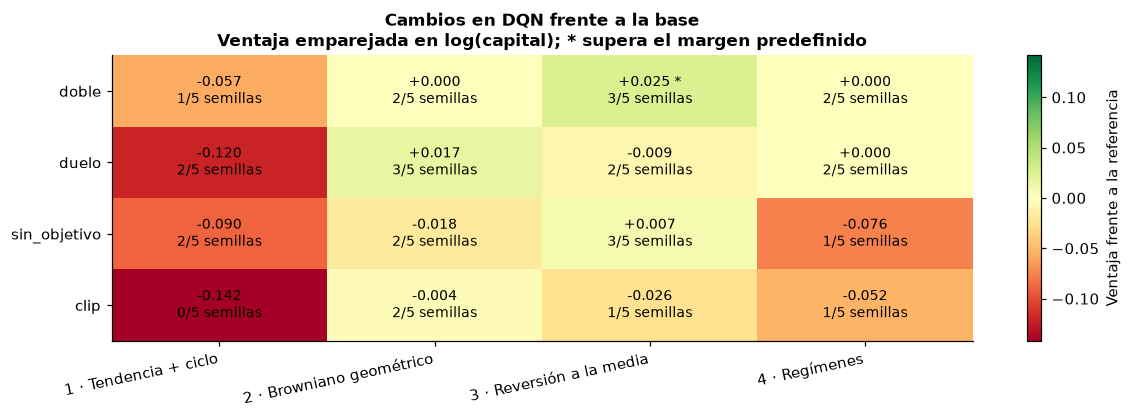

In [3]:
# Esta celda ejecuta el plan completo la primera vez. Después solo recupera las cachés.
run_suite(n_jobs=N_JOBS, groups=["dqn"])
dqn, curves = load_grid("03_grid_dqn")
core = dqn[dqn.mercado.isin(CORE_MARKETS)]
paired = pd.read_csv(RESULTS_DIR / "03_grid_pareadas.csv")
architectures = ["base", "doble", "duelo", "sin_objetivo", "clip"]
display(performance_table(core[core.variante.isin(architectures)]))
effect_figure(paired, architectures[1:], "Cambios en DQN frente a la base", "03_arquitecturas")
plt.show()

La tabla muestra **mediana del retorno**; `x300` significa capital final 300 veces el
inicial, no +300 %. Estos múltiplos pertenecen al generador sintético de tendencia y no
son una previsión financiera. En la figura, el asterisco indica el margen predefinido;
el número inferior informa de cuántas semillas mejoran. Una media grande o una sola
semilla favorable no bastan para declarar una mejora robusta.

## 3. ¿Aporta más información el estado?

Se mantiene todo lo demás y se cambia una categoría de representación:

- **Ventana:** estado original más 20 log-retornos recientes (22 entradas).
- **MA30 + volatilidad:** estado original más distancia relativa a MA30 y desviación de
  20 log-retornos (4 entradas).
- **Ciego:** tendencia anulada, manteniendo posición y dimensiones. Es un placebo de
  ausencia de información de precios, no una estrategia optimizada.

Hipótesis: la historia puede ayudar a reconocer regímenes y niveles de reversión; el
placebo debería perder la capacidad de explotar señal. Estar invertido en un mercado
con deriva positiva puede seguir dando beneficios aun sin información predictiva.

mercado,1 · Tendencia + ciclo,2 · Browniano geométrico,3 · Reversión a la media,4 · Regímenes
variante,,,,
base,x348.4,-5.8%,+16.8%,-7.0%
ventana,x547.9,-11.3%,+30.7%,-3.8%
ma30_vol,x244.9,-6.5%,+47.9%,+7.6%
ciego,x26.6,+0.0%,+0.0%,+0.0%


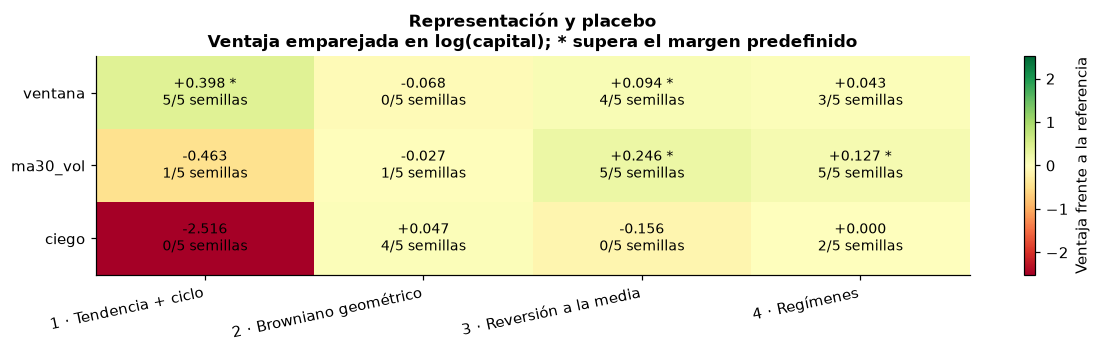

,mercado,variante,mediana,peor,mejor,operaciones
0,browniano,base,-5.8%,-6.6%,-3.1%,7.9
1,browniano,ciego,+0.0%,-6.3%,+0.0%,0.0
8,browniano,ma30_vol,-6.5%,-9.2%,-4.4%,25.6
11,browniano,ventana,-11.3%,-14.2%,-7.6%,90.0
12,regimenes,base,-7.0%,-13.8%,+4.2%,31.7
13,regimenes,ciego,+0.0%,-16.1%,+0.0%,0.0
20,regimenes,ma30_vol,+7.6%,+4.3%,+12.7%,25.4
23,regimenes,ventana,-3.8%,-5.3%,-1.9%,77.5
24,reversion_media,base,+16.8%,+0.0%,+28.1%,25.9
25,reversion_media,ciego,+0.0%,+0.0%,+0.3%,0.0


In [4]:
states = ["base", "ventana", "ma30_vol", "ciego"]
display(performance_table(core[core.variante.isin(states)]))
effect_figure(paired, states[1:], "Representación y placebo", "03_estados")
plt.show()
ranges = seed_ranges(dqn)
display(ranges[ranges.variante.isin(states) & ranges.mercado.isin(CORE_MARKETS)][["mercado", "variante", "mediana", "peor", "mejor", "operaciones"]]
        .style.format({"mediana": formato, "peor": formato, "mejor": formato, "operaciones": "{:.1f}"}))

## 4. Recompensa, costes y especialización

**Log del capital:** solo cambia la señal de aprendizaje a
`log(balance_siguiente / balance_actual)`, con la misma normalización. Su suma coincide
con el crecimiento logarítmico del capital; con γ=0,9 se sigue descontando el futuro.
La hipótesis es reducir el desajuste entre recompensa aditiva y capital compuesto,
especialmente en el browniano. Las métricas siguen calculándose con el balance real.

**Mezcla:** solo cambia la distribución de entrenamiento: 125 episodios de cada mercado,
alternados, frente a 500 de un solo mercado. La normalización sigue ajustándose sobre
train. Se estudia generalidad frente a especialización con **el mismo presupuesto total**.

**Comisiones:** cada agente se entrena y evalúa con 0 %, 0,1 % o 0,5 % por operación.
Se sustituye el coste en recompensa y patrimonio. La hipótesis es que costes mayores
reduzcan la actividad; el entrenamiento puede no conseguirlo.

mercado,1 · Tendencia + ciclo,2 · Browniano geométrico,3 · Reversión a la media,4 · Regímenes
variante,,,,
base,x348.4,-5.8%,+16.8%,-7.0%
log,x457.2,-2.1%,+21.5%,-3.1%
mezcla,x260.6,-6.3%,+0.1%,-16.1%


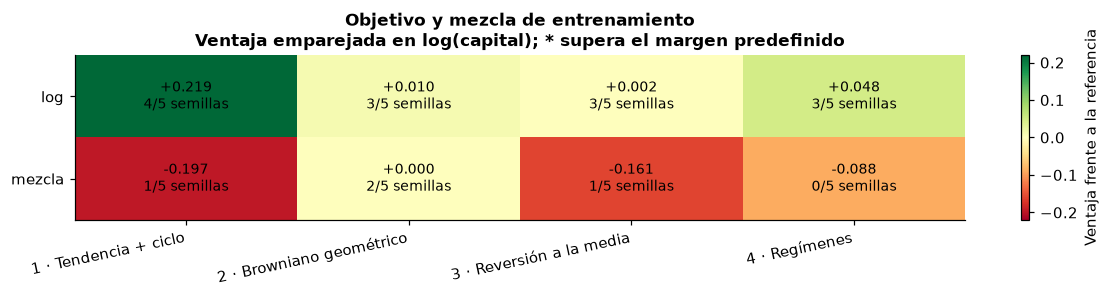

mercado,1 · Tendencia + ciclo,2 · Browniano geométrico,3 · Reversión a la media,4 · Regímenes
variante,,,,
base,x348.4,-5.8%,+16.8%,-7.0%
comision_0,x289.2,-6.1%,+28.2%,-2.7%
comision_05,x314.2,+0.0%,+2.1%,+0.0%


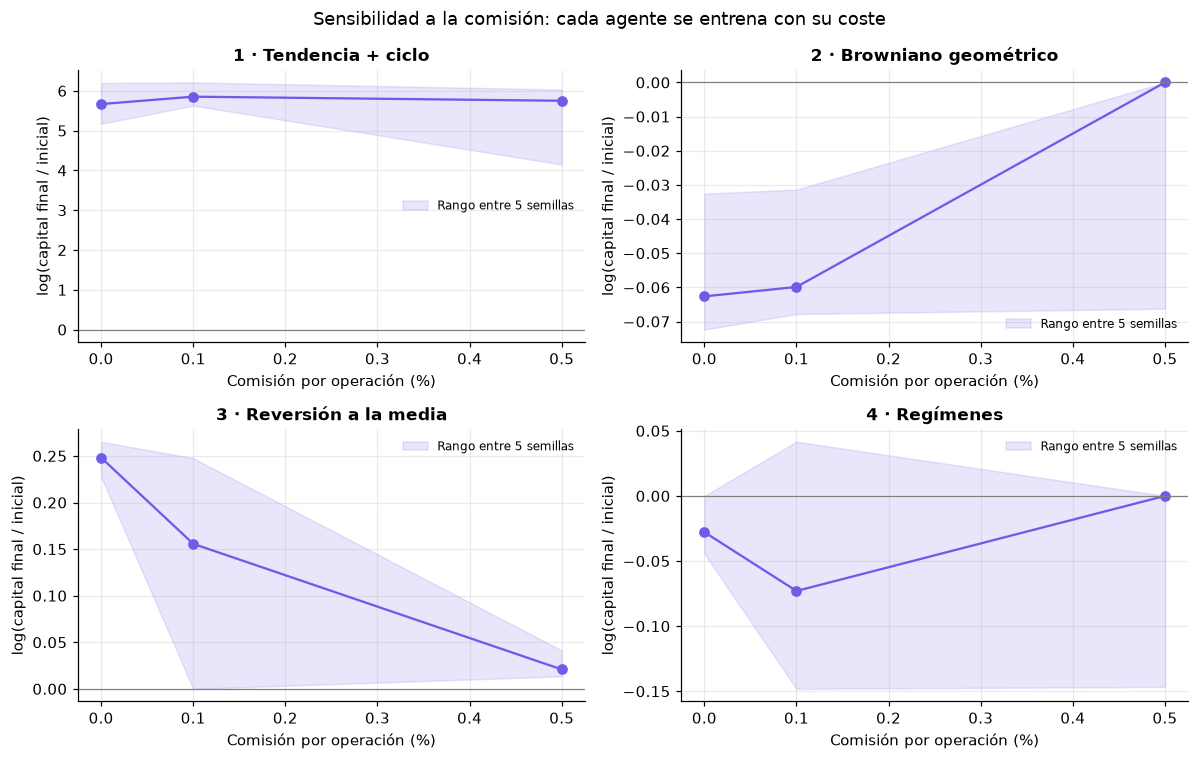

mercado,2 · Browniano geométrico,4 · Regímenes,3 · Reversión a la media,saltos,1 · Tendencia + ciclo,tendencia_persistente
variante,,,,,,
base,7.9,31.7,25.9,4.5,64.2,28.4
comision_0,64.1,108.6,69.2,NaN,61.5,NaN
comision_05,0.1,0.1,1.0,NaN,43.2,NaN


In [5]:
display(performance_table(core[core.variante.isin(["base", "log", "mezcla"])]))
effect_figure(paired, ["log", "mezcla"], "Objetivo y mezcla de entrenamiento", "03_objetivo_mezcla")
plt.show()
display(performance_table(core[core.variante.isin(["comision_0", "base", "comision_05"])]))
commission_figure(dqn)
plt.show()
display(dqn[dqn.variante.isin(["comision_0", "base", "comision_05"])]
        .pivot_table(index="variante", columns="mercado", values="n_trades", aggfunc="median")
        .rename(columns=MARKET_LABELS).round(1))

## 5. Generadores adicionales y referencias

Se usa `register_extra_markets()`: **tendencia persistente**, con cambios de dirección
largos y observables, y **saltos**, una difusión con shocks independientes. Se mantiene
el DQN base. Se espera que el primero ofrezca señal y que el segundo sirva como estrés.

Cambiar el mercado cambia la tarea: no se interpreta una diferencia de retorno entre
dos generadores como mejora causal del algoritmo. Se compara con aleatorio, buy & hold
y no operar **en las mismas series del nuevo mercado y con el mismo coste**.

In [6]:
run_suite(n_jobs=N_JOBS, groups=["baselines"])
baselines = pd.read_csv(RESULTS_DIR / "03_grid_baselines.csv")
extras_markets = ["tendencia_persistente", "saltos"]
extra_rows = dqn[dqn.mercado.isin(extras_markets)].groupby("mercado").retorno_mediana.median().rename("DQN")
refs = baselines[baselines.commission.eq(.001)].pivot(index="mercado", columns="baseline", values="retorno_mediana")
display(refs.join(extra_rows).loc[extras_markets].map(formato))

,aleatorio,buy_hold,no_operar,DQN
mercado,,,,
tendencia_persistente,-7.8%,+17.5%,+0.0%,x2.0
saltos,-25.5%,-22.7%,+0.0%,-0.2%


## 6. S&P 500: una prueba temporal retrospectiva

Se verifica la huella de la copia local antes de utilizarla. **Train 2017–2021,
validación 2022–2023 y evaluación 2024–2025.** En train se muestrean ventanas de 500
precios completamente dentro del periodo. No se ajusta nada con el futuro.

El control **transferencia** se entrena en el browniano y se aplica al histórico;
**real** usa el histórico de train. El único factor es la fuente de entrenamiento:
se mantienen algoritmo, hiperparámetros y periodo de evaluación. La normalización se
ajusta sobre el train de cada fuente mediante el mismo procedimiento.

Hay cinco inicializaciones, pero **una sola trayectoria histórica**, no 400 muestras
independientes ni cinco mercados distintos. El periodo ya estaba disponible en el
Taller 1. No es una prueba prospectiva ni permite extrapolar a inversión real.

,retorno_mediana,peor_semilla,mejor_semilla,operaciones
variante,,,,
real,+12.1%,+5.7%,+39.3%,75.0
transferencia,+34.8%,+0.0%,+44.3%,1.0


baseline,aleatorio,buy_hold,no_operar
mercado,,,
sp500,+2.1%,+43.8%,+0.0%


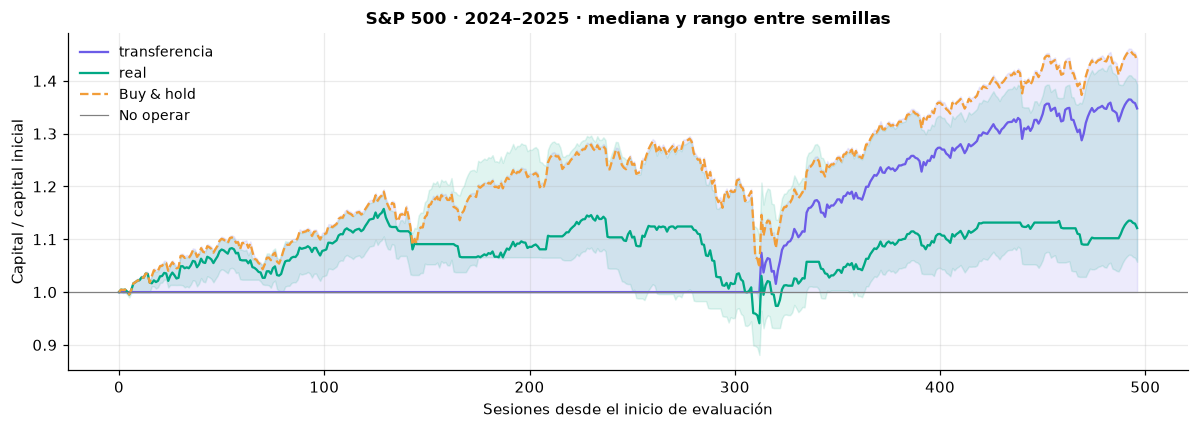

In [7]:
real = dqn[dqn.mercado.eq("sp500")]
display(real.groupby("variante").agg(retorno_mediana=("retorno_mediana", "median"),
        peor_semilla=("retorno_mediana", "min"), mejor_semilla=("retorno_mediana", "max"),
        operaciones=("n_trades", "median")).style.format(
        {"retorno_mediana": formato, "peor_semilla": formato, "mejor_semilla": formato, "operaciones": "{:.1f}"}))
display(refs.loc[["sp500"]].map(formato))
real_figure(dqn, curves)
plt.show()

## 7. A2C frente a A3C

Se conserva la referencia ajustada de 02: 3 entornos, 64 neuronas, Adam, γ=0,9,
t_max=20, α=0,003 en tendencia y 0,001 en el resto; β=0 en reversión y 0,01 en el resto.
Solo cambia el esquema de actualización: A2C reúne los tres rollouts y aplica el
gradiente medio; A3C aplica gradientes locales asíncronos.

Ambos solicitan 500 episodios y ejecutan **504 efectivos**, el redondeo a bloques de 24
que ya hace A3C. Usan las mismas semillas de las series. A2C es reproducible con semillas
fijas; A3C no es reproducible bit a bit por el orden de las actualizaciones.

A2C agrupa los tres entornos en un proceso; A3C usa tres procesos. Los segundos
comparan estas implementaciones, no un coste intr?nseco con id?ntico uso de CPU.
Se ejecutan uno a uno en el mismo equipo. Los tiempos excluyen evaluaciones; A3C
también excluye arranque. No se comparan con los tiempos DQN del pool ni con otro equipo.
Fuente: [A3C](https://proceedings.mlr.press/v48/mniha16.html) y
[A2C](https://stable-baselines3.readthedocs.io/en/master/modules/a2c.html).

In [8]:
run_suite(groups=["actores"])
actors, actor_curves = load_grid("03_grid_actores")
actor_pairs = pd.read_csv(RESULTS_DIR / "03_grid_pareadas_actores.csv")
display(performance_table(actors))
display(actor_pairs[["mercado", "ventaja_log", "semillas_mejoran", "n_semillas", "supera_margen"]].round(3))
display(actors.groupby(["mercado", "variante"]).agg(
    segundos_mediana=("tiempo_s", "median"), segundos_min=("tiempo_s", "min"),
    segundos_max=("tiempo_s", "max"), semillas_convergencia=("episodios_convergencia", "count"), episodios_convergencia=("episodios_convergencia", "median")).round(1))
actors["estado_convergencia"] = [convergence_status(actor_curves[i]) for i in actors.id]
display(pd.crosstab([actors.mercado, actors.variante], actors.estado_convergencia))
assert all(len(actor_curves[i]["retorno"]) == 504 for i in actors.id)

mercado,1 · Tendencia + ciclo,2 · Browniano geométrico,3 · Reversión a la media,4 · Regímenes
variante,,,,
a3c,x500.3,+0.0%,+14.7%,+0.0%
a2c,x509.1,-6.1%,+4.6%,+0.0%


,mercado,ventaja_log,semillas_mejoran,n_semillas,supera_margen
0,tendencia_ciclo,0.085,3,5,False
1,browniano,-0.047,1,5,False
2,reversion_media,0.000,2,5,False
3,regimenes,0.000,1,5,False


segundos_mediana  segundos_min  segundos_max  \
mercado         variante                                                 
browniano       a2c                   37.8          33.1          42.0   
                a3c                   18.8          17.6          29.9   
regimenes       a2c                   41.2          38.9          44.5   
                a3c                   31.7          29.7          35.4   
reversion_media a2c                   43.5          41.4          44.7   
                a3c                   30.3          30.0          31.2   
tendencia_ciclo a2c                   45.9          35.3          47.3   
                a3c                   31.8          30.7          32.9   

                          semillas_convergencia  episodios_convergencia  
mercado         variante                                                 
browniano       a2c                           0                     NaN  
                a3c                           1                    24.0  
regimenes       a2c                           0                     NaN  
                a3c                           0                     NaN  
reversion_media a2c                           3                   480.0  
                a3c                           3                   336.0  
tendencia_ciclo a2c                           5                    72.0  
                a3c                           4                    96.0

estado_convergencia       converge  no mejora  no opera
mercado         variante                               
browniano       a2c              0          5         0
                a3c              1          2         2
regimenes       a2c              0          0         5
                a3c              0          1         4
reversion_media a2c              3          2         0
                a3c              3          1         1
tendencia_ciclo a2c              5          0         0
                a3c              4          0         1

## 8. Auditoría y resultados exportados

El detalle por semilla y por serie permite reconstruir las comparaciones sin inferir
conclusiones a partir de una figura. Los pesos y curvas de entrenamiento están en la
caché local; los CSV y PNG son los resultados legibles. Los agentes experimentales se
identifican con prefijo `03_` y no sustituyen a los oficiales de 01–02.

In [9]:
assert len(dqn) == 260 and len(actors) == 40
assert all(len(curves[i]["retorno"]) == 500 for i in dqn.id)
assert actors.groupby(["mercado", "seed"])["config"].nunique().eq(1).all()
actor_manifest = [{"mercado": r.mercado, "seed": int(r.seed), "variante": r.variante,
                   "config": ast.literal_eval(r.config)} for r in actors.itertuples()]
(RESULTS_DIR / "03_plan_actores.json").write_text(
    json.dumps(actor_manifest, ensure_ascii=False, indent=2), encoding="utf-8")
assert dqn.groupby(["mercado", "variante"]).seed.nunique().eq(5).all()
assert actors.groupby(["mercado", "variante"]).seed.nunique().eq(5).all()
assert all(len(curves[row.id]["eval_retornos"]) == (1 if row.mercado == "sp500" else 400)
           for row in dqn.itertuples())
series = export_series(dqn, curves, "03_grid_series_dqn")
actor_series = export_series(actors, actor_curves, "03_grid_series_actores")
ranges.to_csv(RESULTS_DIR / "03_grid_rangos.csv", index=False)
ranges.merge(paired, on=["mercado", "variante"], how="left").to_csv(
    RESULTS_DIR / "03_grid_resumen_dqn.csv", index=False)
for seed in range(5):
    states = [curves[r.id]["model_state"] for r in dqn[(dqn.variante == "mezcla") & (dqn.seed == seed)].itertuples()]
    assert all(all(torch.equal(states[0][k], state[k]) for k in states[0]) for state in states[1:])
print(f"Verificado: {len(dqn) + len(actors)} entrenamientos, {len(series) + len(actor_series):,} evaluaciones por serie.")
print("Configuraciones: 03_plan.json; detalles: 03_grid_*.csv; resúmenes: 03_extras_*.csv; figuras: figures/03_*.png.")
print("Reproducción: ejecutar este notebook. La caché evita repetir lo completado.")

Verificado: 300 entrenamientos, 116,010 evaluaciones por serie.
Configuraciones: 03_plan.json; detalles: 03_grid_*.csv; resúmenes: 03_extras_*.csv; figuras: figures/03_*.png.
Reproducción: ejecutar este notebook. La caché evita repetir lo completado.


# 03 · Resultados y conclusiones

Experimentos posteriores al test oficial, con cinco semillas por condición y una
sola modificación respecto a la referencia. Los resultados de 01 y 02 no cambian.
Se utilizan 400 series sintéticas desde 600.000; las parejas comparten precios y
semillas. Los márgenes son descriptivos, no contrastes de significación.

### La representación aporta más que las variantes de arquitectura

Mediana del retorno entre cinco entrenamientos, medida sobre las mismas series:

| Mercado | DQN base | + 20 retornos | + MA30 y volatilidad |
|---|---:|---:|---:|
| Tendencia y ciclo | x348,4 | x547,9 | x244,9 |
| Browniano | −5,8 % | −11,3 % | −6,5 % |
| Reversión | +16,8 % | +30,7 % | +47,9 % |
| Regímenes | −7,0 % | −3,8 % | +7,6 % |

La ventana supera el margen emparejado en tendencia y reversión: ventajas log
de +0,398 y +0,094, con 5/5 y 4/5 semillas que mejoran. MA30 y volatilidad lo
superan en reversión y regímenes: +0,246 y +0,127, con 5/5 en ambos.
Las dos representaciones empeoran el browniano y MA30/volatilidad empeora la
tendencia. El resultado favorece adaptar la información al problema; añadir
variables no garantiza mejorar. También aumenta el número de pesos de entrada,
y este experimento no separa el aporte de MA30 del de volatilidad.

Double DQN supera el margen solo en reversión (+0,025, 3/5 semillas), con menos
consistencia que las ampliaciones del estado. Duelo, quitar la red objetivo y
recortar la recompensa no superan el margen en ningún mercado. El clipping
perjudica a las cinco semillas de tendencia. Esto describe esta configuración
y este presupuesto, no la utilidad general de esos métodos.

### Recompensa, placebo, mezcla y comisiones

- La recompensa logarítmica no supera el margen en ningún mercado. En tendencia
  queda cerca (+0,219 frente a log(1,25)=0,223, con 4/5 semillas que mejoran).
  No se cambia el umbral después de verlo. Que suba la mediana agregada no
  implica que mejore la comparación emparejada: la tabla muestra ambas.
- Al anular la tendencia, el agente compra y mantiene en el mercado alcista
  (x26,6) y la mediana queda en 0 % en los otros tres. Puede ganar por la deriva
  sin predecir precios. En reversión pierde la capacidad útil de la referencia.
- Mezclar los cuatro generadores con el mismo presupuesto total no mejora a la
  especialización: en reversión cae de +16,8 % a +0,1 %, y en regímenes de −7,0 %
  a −16,1 %. Cada mercado aporta 125 episodios en vez de 500. No se puede inferir
  que una política general sea imposible con otro estado o más entrenamiento.
  Se comprobó que las réplicas de una misma semilla de mezcla tienen los mismos
  pesos al evaluar los cuatro mercados: no hay adaptación oculta al mercado.
- El agente adapta su actividad al coste. En reversión pasa de 69,2 operaciones
  con comisión 0 %, a 25,9 con 0,1 % y a 1,0 con 0,5 %; el retorno mediano pasa
  de +28,2 % a +16,8 % y +2,1 %. En browniano y regímenes, con el coste alto la
  actividad es prácticamente nula. Quitar costes cambia también el aprendizaje:
  no se espera una curva de rentabilidad monótona entre políticas entrenadas por
  separado. La comisión es un cambio en la tarea, no una mejora del algoritmo.

### Mercados adicionales e histórico real

En tendencia persistente, DQN obtiene +101,5 % frente a +17,5 % de buy & hold;
el rango de las medianas entre semillas es +81,0 % a +106,9 %. En saltos queda
en −0,2 %, frente a −22,7 % de buy & hold y 0 % de no operar. La estrategia
se beneficia de tendencias observables y casi deja de operar cuando dominan
los shocks independientes; todavía queda por debajo de no operar en ese caso.

En el S&P 500, entrenar con 2017–2021 y evaluar en 2024–2025 da una mediana
de +12,1 % y 75 operaciones, frente a +43,8 % y una operación de buy & hold.
La transferencia desde entrenamiento browniano da +34,8 % de mediana, con
dispersión entre 0 % y +44,3 %. No hay evidencia de que entrenar con el histórico
real produzca una estrategia mejor en este periodo. La ventaja emparejada entre
inicializaciones y las medianas agregadas pueden tener signos distintos, por lo
que no se presenta una de ellas como prueba aislada de superioridad.

El histórico es una trayectoria única, ya disponible en el Taller 1. Cinco
inicializaciones no son cinco pruebas históricas independientes. El análisis
es retrospectivo, conserva la partición temporal y la normalización solo de
train, y no permite extrapolar a inversión real.

### A2C frente a A3C

Se mantienen la red, los parámetros de 02 y el presupuesto de 504 episodios
efectivos. Solo cambia la variante de actualización, sin reajustar A2C.

| Mercado | A3C | A2C | Ventaja log de A2C | Semillas que mejoran |
|---|---:|---:|---:|---:|
| Tendencia y ciclo | x500,3 | x509,1 | +0,085 | 3/5 |
| Browniano | +0,0% | -6,1% | -0,047 | 1/5 |
| Reversión | +14,7% | +4,6% | +0,000 | 2/5 |
| Regímenes | +0,0% | +0,0% | +0,000 | 1/5 |

A2C no supera el margen predefinido en ningún mercado. En tendencia las
medianas son próximas; en reversión su mediana es menor, aunque su mejor
semilla es mejor. No se elige una ejecución aislada como representante.

Los parámetros proceden de la referencia A3C; no se ha buscado una
configuración óptima propia para A2C. El resultado responde a esta comparación
controlada, no a una clasificación universal de algoritmos.

A2C agrupa tres entornos en un proceso y A3C utiliza tres procesos. Los
tiempos comparan estas implementaciones y no un coste intrínseco con igual
uso de CPU. Se muestran en el notebook junto al número de semillas que
cumplen el criterio de convergencia. Alcanzar el 90 % del nivel final no
demuestra que la política se haya estabilizado.

### Alcance de las conclusiones

Se completan las ideas de partida sin combinar cambios ni reajustar tras ver
las nuevas series. Las tablas conservan el detalle por semilla y los CSV por
serie permiten auditar las parejas. La variación entre semillas y las múltiples
comparaciones impiden interpretar un asterisco del margen como significación
estadística. Los tiempos DQN con varios entrenamientos simultáneos no comparan
la velocidad de las variantes. Los de actor-crítico se miden secuencialmente en
el mismo equipo, excluyendo evaluación y, en A3C, arranque de procesos.

La verificación incluye 63 pruebas sin fallos ni errores y una omisión por falta
del material bruto del enunciado. Los controles cubren equivalencia de la base,
causalidad de los indicadores, cuentas de comisión, objetivos Double DQN,
presupuesto de A2C y evaluación en lote. Los cuatro generadores y el entorno
original permanecen intactos.
